# All Storm Best-Track Overview

This notebook loads every cataloged Atlantic ATCF best-track file, colors each track segment by maximum sustained wind, and exports one combined map.

**Pipeline**

```text
storm catalog -> ATCF files -> unique advisory points -> colored segments -> overview PNG
```

## 1. Imports

The notebook uses pandas for tabular track data, Matplotlib for rendering, and Cartopy for the geographic map.

In [69]:
import csv
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

## 2. Paths and options

The project directory is detected automatically, so the notebook works when launched from the repository root. Change the output options here before running the remaining cells.

In [70]:
def find_project_paths(start: Path | None = None) -> tuple[Path, Path]:
    """Return the repository root and reports/per_storm project directory."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        project = candidate / "reports" / "per_storm"
        if (project / "data" / "tracks" / "storm_dat_files.md").is_file():
            return candidate, project
        if (candidate / "data" / "tracks" / "storm_dat_files.md").is_file():
            repo_root = candidate.parents[1] if candidate.name == "per_storm" else candidate
            return repo_root, candidate
    raise FileNotFoundError(
        "Could not locate reports/per_storm/data/tracks/storm_dat_files.md"
    )


REPO_ROOT, PROJECT_ROOT = find_project_paths()
DATA_ROOT = PROJECT_ROOT / "data" / "tracks"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "all_tracks"

DPI = 300
FORMATS = ("png",)
SHOW_FIGURE = False
BRANDED = False
OUTPUT_STEM = "2003_2025_all_storm_best_tracks_without_branding"

print("Data:  ", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Data:   C:\github\ipynb\data\tracks
Output: C:\github\ipynb\outputs\all_tracks


## 3. Read the storm catalog

Each catalog record keeps the year and storm name together with its local `.dat` path. Keeping this metadata is necessary for titles and date-range summaries.

In [71]:
@dataclass(frozen=True)
class CatalogEntry:
    year: str
    storm: str
    mesh: str
    dat_path: Path


def load_catalog(data_root: Path) -> list[CatalogEntry]:
    """Read storm_dat_files.md and resolve every copied ATCF file."""
    report_path = data_root / "storm_dat_files.md"
    entries: list[CatalogEntry] = []

    for line in report_path.read_text(encoding="utf-8").splitlines():
        if not line.startswith("|"):
            continue
        cells = [cell.strip() for cell in line.strip("|").split("|")]
        if not cells or cells[0] in {"year", "---:"}:
            continue
        if len(cells) != 6:
            raise ValueError(f"Unexpected catalog row: {line}")

        year, storm, mesh, found, _comparisons, source_path = cells
        if found.lower() != "yes":
            continue
        source_name = Path(source_path.strip("`")).name
        dat_path = data_root / f"{year}_{storm}" / source_name
        if not dat_path.is_file():
            raise FileNotFoundError(f"Cataloged ATCF file is missing: {dat_path}")
        entries.append(CatalogEntry(year, storm, mesh, dat_path))

    if not entries:
        raise ValueError(f"No usable storm entries found in {report_path}")
    return entries

## 4. Parse ATCF track files

ATCF coordinates are stored in tenths of a degree, such as `286N` or `969W`. Repeated timestamps represent wind-radius records around the same center, so only one center point per timestamp is retained.

In [72]:
ATCF_DATETIME_FORMAT = "%Y%m%d%H"


def parse_coordinate(value: str) -> float:
    """Convert an ATCF coordinate from tenths of a degree to decimal degrees."""
    match = re.fullmatch(r"(\d+)([NSEW])", value.strip().upper())
    if not match:
        raise ValueError(f"Invalid ATCF coordinate: {value!r}")
    magnitude = int(match.group(1)) / 10.0
    return -magnitude if match.group(2) in {"S", "W"} else magnitude


def load_atcf_track(dat_path: Path) -> pd.DataFrame:
    """Load the fields needed to plot one ATCF best track."""
    parsed_rows = []
    filtered_marker_rows = 0
    with dat_path.open(newline="", encoding="utf-8") as handle:
        for line_number, fields in enumerate(csv.reader(handle), start=1):
            fields = [field.strip() for field in fields]
            if not fields or all(not field for field in fields):
                continue
            if len(fields) < 11:
                raise ValueError(
                    f"{dat_path}:{line_number} has {len(fields)} fields; expected at least 11"
                )
            
            storm_name = fields[27].strip().upper() if len(fields) > 27 else ""
            if storm_name == "INVEST" or storm_name.startswith("GENESIS"):
                filtered_marker_rows += 1
                continue
            try:
                parsed_rows.append(
                    {
                        "basin": fields[0],
                        "storm_number": fields[1],
                        "time": pd.to_datetime(
                            fields[2], format=ATCF_DATETIME_FORMAT, errors="raise"
                        ),
                        "technique": fields[4],
                        "latitude": parse_coordinate(fields[6]),
                        "longitude": parse_coordinate(fields[7]),
                        "vmax_kt": pd.to_numeric(fields[8], errors="coerce"),
                        "pressure_hpa": pd.to_numeric(fields[9], errors="coerce"),
                        "status": fields[10],
                    }
                )
            except ValueError as exc:
                raise ValueError(f"{dat_path}:{line_number}: {exc}") from exc

    track = pd.DataFrame(parsed_rows)
    track.attrs["filtered_marker_rows"] = filtered_marker_rows
    if track.empty:
        return track
    return (
        track.sort_values("time")
        .drop_duplicates(subset=["time"], keep="first")
        .reset_index(drop=True)
    )

## 5. Prepare map geometry

Adjacent advisory points become line segments. Each segment receives the mean wind speed of its two endpoints, converted from knots to miles per hour.

In [73]:
KNOTS_TO_MPH = 1.15078
WIND_SCALE_MIN_MPH = 0.0
WIND_SCALE_MAX_MPH = 157.0

WIND_COLORMAP = LinearSegmentedColormap.from_list(
    "cera_wind",
    [
        (0.0000, "#D9F0F7"),
        (0.2484, "#1976B5"),
        (0.4713, "#F8E731"),
        (0.6115, "#EA832F"),
        (0.7070, "#D21835"),
        (0.8280, "#69162D"),
        (1.0000, "#000000"),
    ],
)


def full_data_extent(
    tracks: Iterable[tuple[CatalogEntry, pd.DataFrame]],
) -> list[float]:
    """Calculate a padded extent containing every advisory point."""
    frames = [track for _entry, track in tracks]
    lon_min = min(float(track["longitude"].min()) for track in frames)
    lon_max = max(float(track["longitude"].max()) for track in frames)
    lat_min = min(float(track["latitude"].min()) for track in frames)
    lat_max = max(float(track["latitude"].max()) for track in frames)
    lon_pad = max((lon_max - lon_min) * 0.03, 2.0)
    lat_pad = max((lat_max - lat_min) * 0.05, 2.0)
    return [
        max(-180.0, lon_min - lon_pad),
        min(180.0, lon_max + lon_pad),
        max(-90.0, lat_min - lat_pad),
        min(90.0, lat_max + lat_pad),
    ]


def collect_segments(
    tracks: Iterable[tuple[CatalogEntry, pd.DataFrame]],
) -> tuple[np.ndarray, np.ndarray]:
    """Build valid track segments and their mean endpoint winds in mph."""
    segments: list[np.ndarray] = []
    wind_speeds: list[float] = []

    for _entry, track in tracks:
        points = track[["longitude", "latitude"]].to_numpy(dtype=float)
        winds = track["vmax_kt"].to_numpy(dtype=float) * KNOTS_TO_MPH
        for index in range(len(points) - 1):
            segment = points[index : index + 2]
            endpoint_winds = winds[index : index + 2]
            if not np.isfinite(segment).all() or not np.isfinite(endpoint_winds).any():
                continue
            segments.append(segment)
            wind_speeds.append(float(np.nanmean(endpoint_winds)))

    if not segments:
        raise ValueError("No valid track segments were found")
    segment_array = np.asarray(segments, dtype=float)
    wind_array = np.asarray(wind_speeds, dtype=float)
    order = np.argsort(wind_array, kind="stable")
    return segment_array[order], wind_array[order]

## 6. Define the map renderer

A pale underlay keeps overlapping tracks visible. Stronger-wind segments are drawn last so the most intense portions remain readable. Branding is optional and is disabled in the options cell by default.

In [74]:
def add_base_features(ax) -> None:
    """Add consistent Natural Earth background features."""
    #MORE GREYISH COLOR FOR THE SEA
    #ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#c9d9df", zorder=0)
    #CERA BLUE COLOR FOR THE SEA
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#D8DBDE", edgecolor="none", linewidth=0, zorder=0)

    #ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#FFFFFF", zorder=0)
    ax.add_feature(
        cfeature.LAKES.with_scale("10m"), facecolor="#D8DBDE",
        edgecolor="#A8A8A8", linewidth=0.25, zorder=1,
    )
    ax.add_feature(
        cfeature.RIVERS.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.22, alpha=0.75, zorder=1,
    )
    ax.add_feature(
        cfeature.COASTLINE.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.45, alpha=0.65, zorder=2,
    )
    ax.add_feature(
        cfeature.BORDERS.with_scale("10m"), edgecolor="#CFCFCF",
        linewidth=0.30, alpha=0.55, zorder=2,
    )
    ax.add_feature(
        cfeature.STATES.with_scale("10m"), edgecolor="#CFCFCF",
        linewidth=0.30, alpha=0.55, zorder=2,
    )


def export_overview(
    tracks: list[tuple[CatalogEntry, pd.DataFrame]],
    output_dir: Path,
    formats: Iterable[str],
    dpi: int,
    show: bool,
    branded: bool = False,
    output_stem: str = "all_storm_best_tracks",
) -> list[Path]:
    """Render and export the combined storm-track overview."""
    plt.rcParams.update(
        {
            "figure.dpi": 130,
            "savefig.dpi": 600,
            "font.family": "DejaVu Sans",
            "axes.titleweight": "bold",
            "axes.labelsize": 10,
            "axes.titlesize": 14,
        }
    )

    segments, winds_mps = collect_segments(tracks)
    norm = Normalize(vmin=WIND_SCALE_MIN_MPH, vmax=WIND_SCALE_MAX_MPH, clip=True)
    projection = ccrs.PlateCarree()

    fig = plt.figure(figsize=(14.0, 9.0), constrained_layout=False)
    map_height = 0.60 if branded else 0.5
    ax = fig.add_axes([0.055, 0.145, 0.89, map_height], projection=projection)
    extent = full_data_extent(tracks)
    extent[1] = min(extent[1], -25.0)
    ax.set_extent(extent, crs=projection)
    add_base_features(ax)
    ax.gridlines(
        draw_labels=False, linewidth=0.28, color="#9aa5ad",
        alpha=0.42, linestyle=(0, (2, 3)),
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.55)
        spine.set_edgecolor("#4b5563")

    ax.add_collection(
        LineCollection(
            segments, colors="#f8fafc", linewidths=3.0, alpha=0.78,
            transform=projection, zorder=4,
        )
    )
    colored_tracks = LineCollection(
        segments, cmap=WIND_COLORMAP, norm=norm, linewidths=2.3, alpha=0.92,
        transform=projection, zorder=5,
    )
    colored_tracks.set_array(winds_mps)
    ax.add_collection(colored_tracks)

    years = [int(entry.year) for entry, _track in tracks]
    advisory_count = sum(len(track) for _entry, track in tracks)
    if branded:
        fig.text(
            0.50, 0.952, f"CERA Hindcast Best Tracks ({min(years)}-{max(years)})",
            ha="center", va="center", fontsize=19, fontweight="bold", color="#111827",
        )
        fig.text(
            0.50, 0.915,
            f"{len(tracks)} Atlantic storm events | {advisory_count:,} advisory points | "
            "Track color shows local wind intensity",
            ha="center", va="center", fontsize=11.5, color="#4b5563",
        )
        fig.add_artist(
            Line2D(
                [0.055, 0.50], [0.892, 0.892], transform=fig.transFigure,
                color="#2b8cbe", linewidth=1.25, alpha=0.82,
            )
        )
        fig.add_artist(
            Line2D(
                [0.50, 0.945], [0.892, 0.892], transform=fig.transFigure,
                color="#2a9d62", linewidth=1.25, alpha=0.82,
            )
        )

    colorbar_ax = fig.add_axes([0.24, 0.082, 0.52, 0.026])
    colorbar = fig.colorbar(colored_tracks, cax=colorbar_ax, orientation="horizontal")
    colorbar.set_label(r"Maximum sustained wind (mph)", fontsize=10.5, color="#374151")
    colorbar.set_ticks(np.arange(0, 158, 10))
    colorbar.ax.tick_params(labelsize=9, colors="#4b5563", width=0.5)
    colorbar.outline.set_linewidth(0.55)
    colorbar.outline.set_edgecolor("#6b7280")

    if branded:
        logo_path = REPO_ROOT / "assets" / "cera_logo.png"
        if logo_path.is_file():
            logo_ax = fig.add_axes([0.055, 0.053, 0.036, 0.056])
            logo_ax.imshow(plt.imread(logo_path), interpolation="lanczos")
            logo_ax.set_axis_off()
        fig.text(
            0.096, 0.075, "Coastal Emergency Risks Assessment",
            ha="left", va="center", fontsize=7.6, fontweight="bold", color="#263238",
        )
        fig.text(
            0.945, 0.075, f"ATCF best-track archive | {min(years)}-{max(years)}",
            ha="right", va="center", fontsize=8.0, color="#6b7280",
        )

    output_dir.mkdir(parents=True, exist_ok=True)
    output_paths = []
    for file_format in formats:
        output_path = output_dir / f"{output_stem}.{file_format}"
        fig.savefig(output_path, dpi=dpi, facecolor="white")
        output_paths.append(output_path)

    if show:
        plt.show()
    else:
        plt.close(fig)
    return output_paths

## 7. Load and inspect all tracks

This cell validates the catalog and parses every storm before plotting. The summary makes it easy to spot an incomplete dataset.

In [75]:
catalog = load_catalog(DATA_ROOT)
tracks = []
skipped_tracks = []
for entry in catalog:
    track = load_atcf_track(entry.dat_path)
    if track.empty:
        skipped_tracks.append(f"{entry.year} {entry.storm}")
        continue
    tracks.append((entry, track))

advisory_count = sum(len(track) for _entry, track in tracks)
filtered_marker_rows = sum(track.attrs.get("filtered_marker_rows", 0) for _entry, track in tracks)
wind_speeds_mph = (
    pd.concat([track["vmax_kt"] for _entry, track in tracks], ignore_index=True).dropna()
    * KNOTS_TO_MPH
)
year_values = [int(entry.year) for entry, _track in tracks]

print(f"Tracks:           {len(tracks)}")
print(f"Filtered INVEST/GENESIS rows: {filtered_marker_rows}")
print(f"Empty tracks after filtering: {len(skipped_tracks)}")
print(f"Years:            {min(year_values)}-{max(year_values)}")
print(f"Advisory points:  {advisory_count:,}")
print(f"Wind range:       {wind_speeds_mph.min():.1f}-{wind_speeds_mph.max():.1f} mph")

Tracks:           70
Filtered INVEST/GENESIS rows: 0
Empty tracks after filtering: 0
Years:            2003-2025
Advisory points:  2,501
Wind range:       11.5-184.1 mph


## 8. Render, save, and display

The map is saved first and then displayed from the PNG. This keeps the inline result consistent with the exported figure.

Saved: C:\github\ipynb\outputs\all_tracks\2003_2025_all_storm_best_tracks_without_branding.png


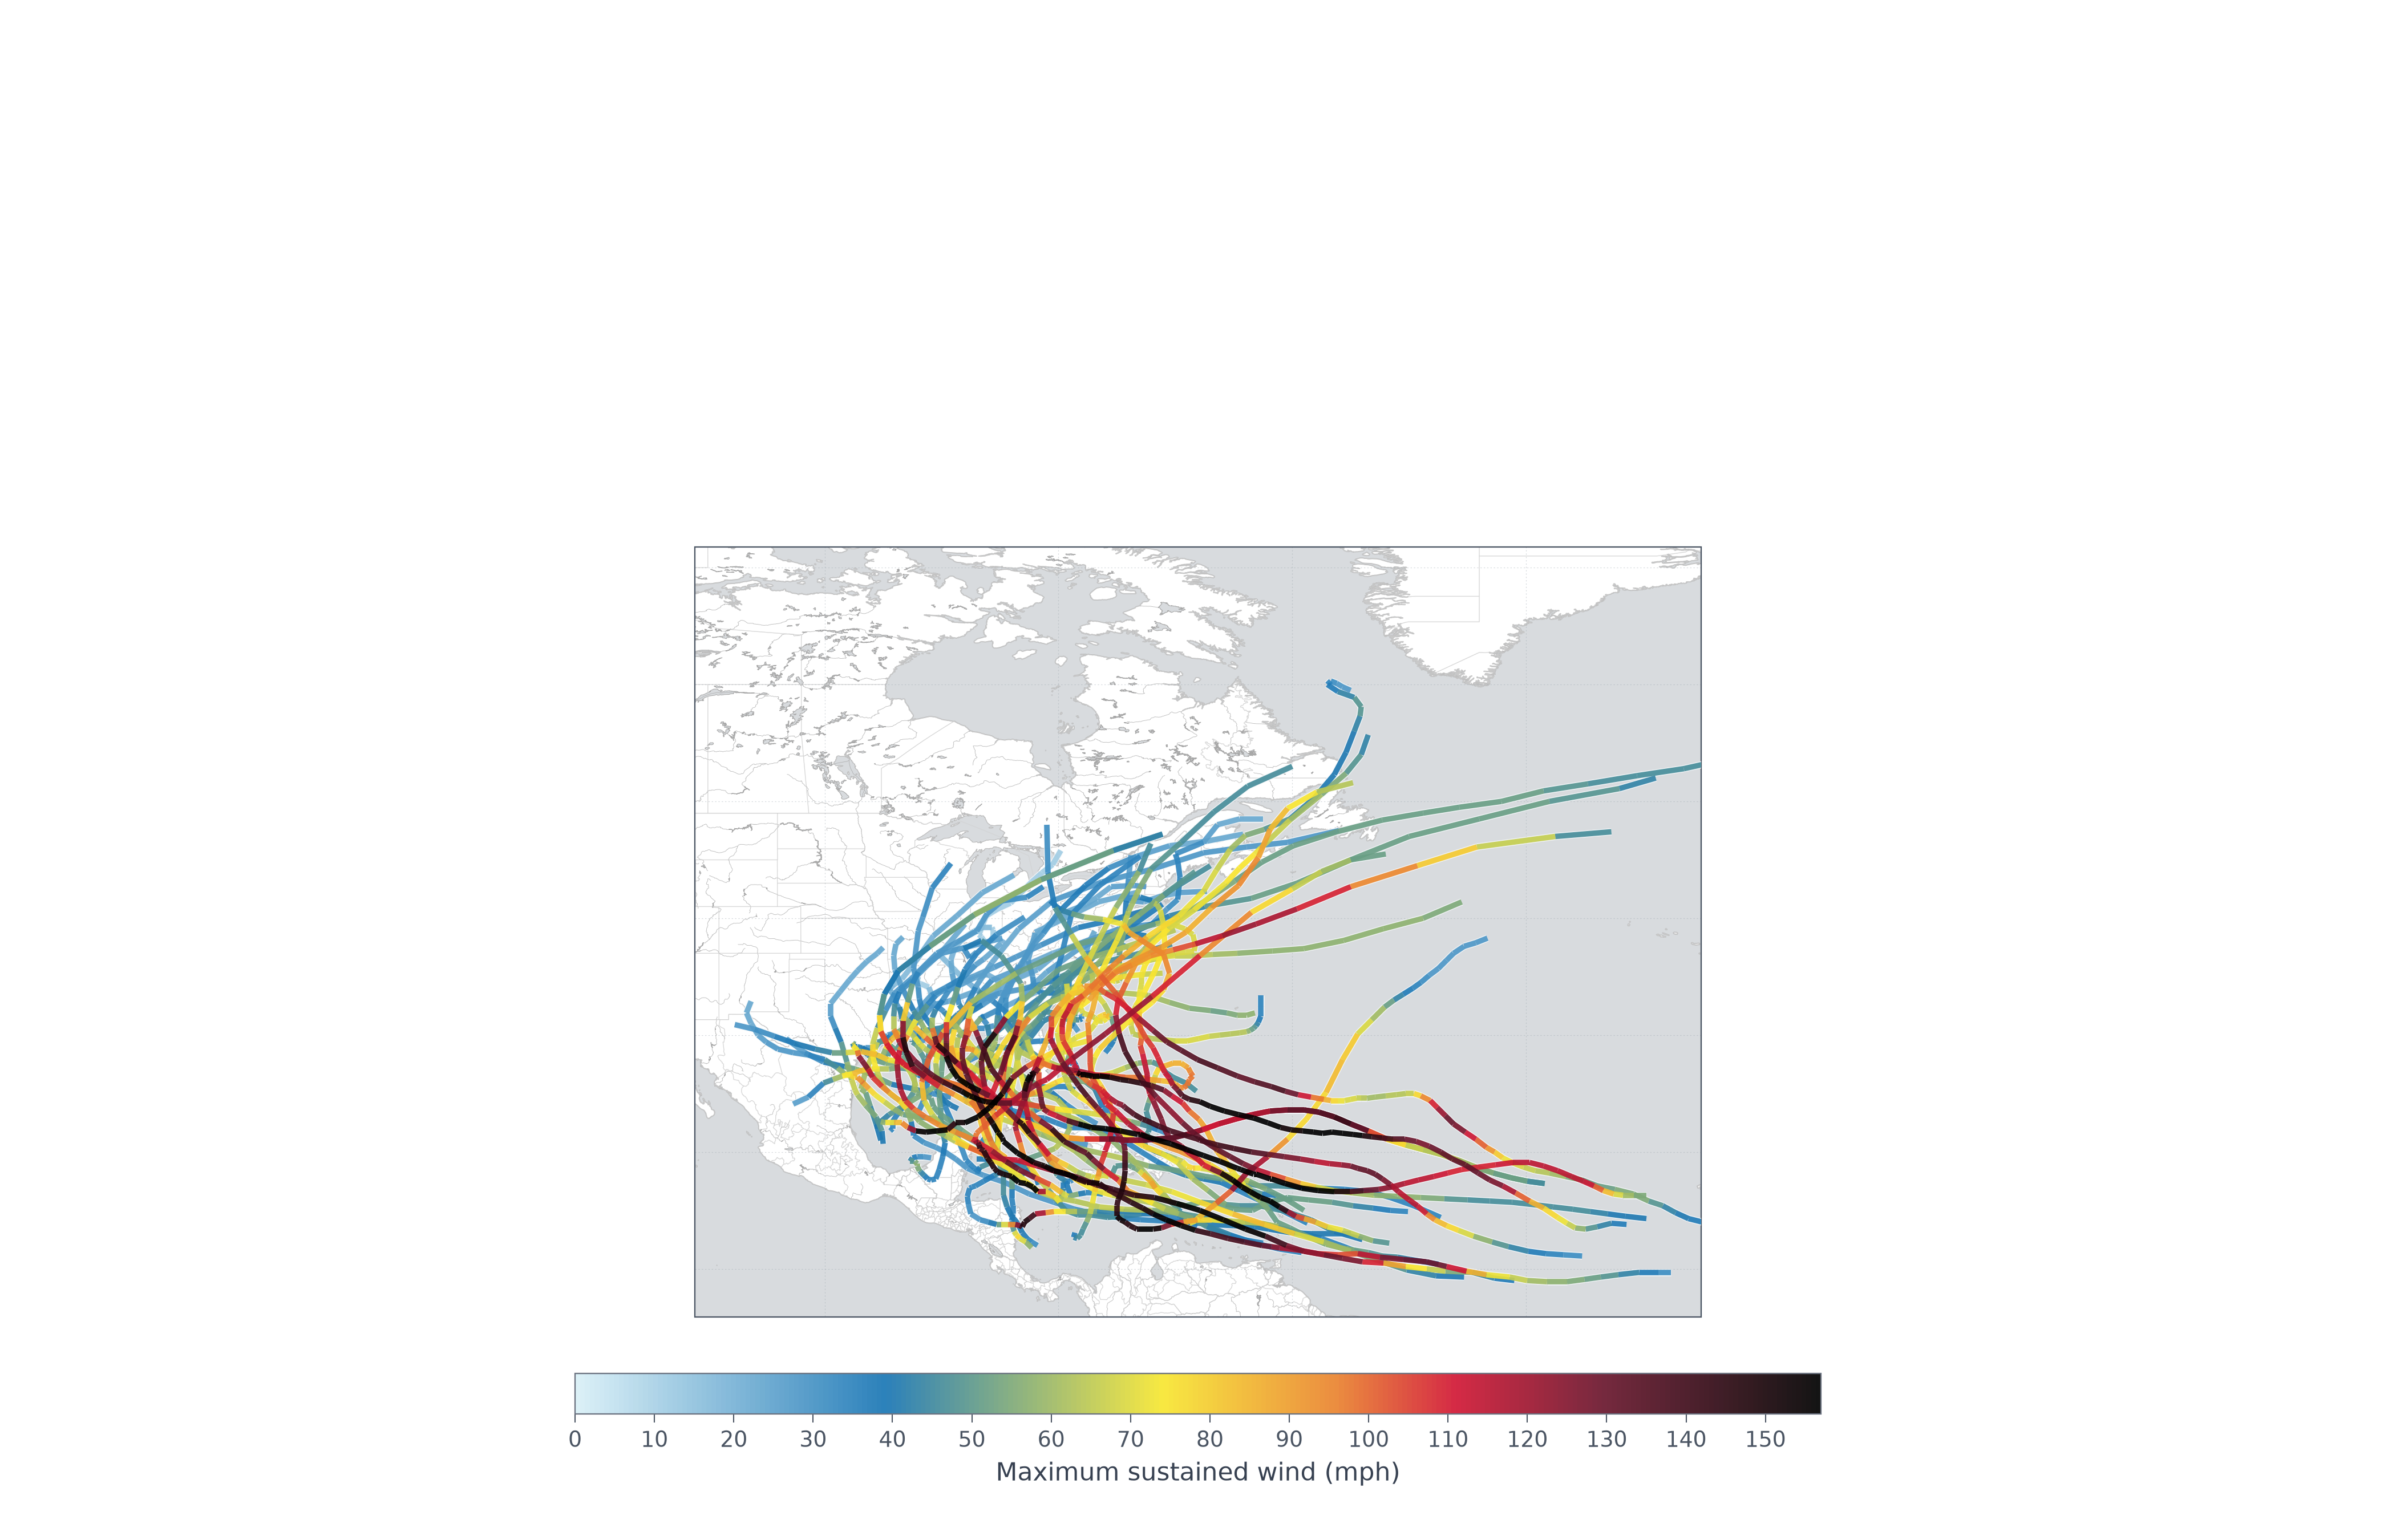

In [76]:
output_paths = export_overview(
    tracks,
    output_dir=OUTPUT_DIR,
    formats=FORMATS,
    dpi=DPI,
    show=SHOW_FIGURE,
    branded=BRANDED,
    output_stem=OUTPUT_STEM,
)

for output_path in output_paths:
    print("Saved:", output_path)

png_path = next((path for path in output_paths if path.suffix.lower() == ".png"), None)
if png_path is not None:
    display(Image(filename=str(png_path)))

## 9. Done

The exported map is under `reports/per_storm/outputs/all_tracks/`. To change resolution, formats, branding, or the output filename, edit only the options cell and rerun from there.